# 02 XGBoost

Official run: CPU (see `docs/decisions.md`, 2026-11-12). Uses the GPU automatically if one is present.

## Setup

In [1]:
# Setup: in Colab, clone the repo and install packages. Locally, use the checkout.
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import userdata
    token = userdata.get('GH_TOKEN')
    if not os.path.exists('/content/credit-card-fraud-detection'):
        !git clone -q https://{token}@github.com/VanshSharmaPES/credit-card-fraud-detection.git /content/credit-card-fraud-detection
    %cd /content/credit-card-fraud-detection
    !pip install -q -r requirements/base.txt -r requirements/xgboost.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
!{sys.executable} src/data.py
sys.path.append('src')

Raw rows: 284807, raw frauds: 492
Duplicates dropped: 1081
Rows after cleaning: 283726, frauds: 473
train rows:  170235  frauds:  284  fraud share: 0.1668%
val   rows:   56745  frauds:   94  fraud share: 0.1657%
test  rows:   56746  frauds:   95  fraud share: 0.1674%
Class weight (train normal / train fraud): 169951 / 284 = 598.4190


In [2]:
import json
import random
import shutil
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from data import load_splits
from evaluate import evaluate_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Use the GPU when there is one. The official run is on CPU (docs/decisions.md).
def gpu_name():
    if shutil.which('nvidia-smi') is None:
        return None
    out = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True)
    return out.stdout.strip().splitlines()[0] if out.returncode == 0 and out.stdout.strip() else None

GPU = gpu_name()
DEVICE = 'cuda' if GPU else 'cpu'
def cpu_name():
    import platform
    try:
        for line in open('/proc/cpuinfo'):
            if line.startswith('model name'):
                return line.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

HARDWARE = f'Colab {GPU}' if (GPU and IN_COLAB) else (GPU or f'CPU: {cpu_name()} ({os.cpu_count()} threads)')
print('xgboost', xgb.__version__, '| device:', DEVICE, '| hardware:', HARDWARE)
if GPU is None:
    print('No GPU found: running on CPU.')

FIG_DIR, MODEL_DIR = Path('figures'), Path('models')
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'legend.frameon': False,
})

xgboost 3.4.1 | device: cpu | hardware: CPU: AMD Ryzen 5 5600H with Radeon Graphics (12 threads)
No GPU found: running on CPU.


## Load the data

In [3]:
(X_train, y_train, X_val, y_val, X_test, y_test,
 rowid_val, rowid_test, amount_val, amount_test) = load_splits()

CLASS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print('Train / val / test rows:', len(X_train), len(X_val), len(X_test))
print('Features:', X_train.shape[1])
print(f'Class weight (train normal / train fraud): {CLASS_WEIGHT:.4f}')
assert X_train.shape[1] == 30
assert round(CLASS_WEIGHT, 4) == 598.4190, "Class weight differs from the data.py summary"

Train / val / test rows: 170235 56745 56746
Features: 30
Class weight (train normal / train fraud): 598.4190


## Train

In [4]:
model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=6, scale_pos_weight=CLASS_WEIGHT,
    eval_metric='aucpr', early_stopping_rounds=50, device=DEVICE, random_state=SEED,
)
start = time.perf_counter()
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100)
train_seconds = time.perf_counter() - start
print(f'Best iteration: {model.best_iteration} | val PR-AUC: {model.best_score:.4f} | {train_seconds:.1f} s')

[0]	validation_0-aucpr:0.51442


[100]	validation_0-aucpr:0.74492


[200]	validation_0-aucpr:0.78414


[300]	validation_0-aucpr:0.78802


[315]	validation_0-aucpr:0.78662


Best iteration: 265 | val PR-AUC: 0.7888 | 6.7 s


## Predict

In [5]:
# predict_proba uses the best iteration from early stopping
p_val = model.predict_proba(X_val)[:, 1]
start = time.perf_counter()
p_test = model.predict_proba(X_test)[:, 1]
predict_seconds = time.perf_counter() - start
print(f'Test prediction: {predict_seconds:.3f} s for {len(X_test):,} rows')

Test prediction: 0.047 s for 56,746 rows


## Evaluate

In [6]:
# Argument names match src/evaluate.py on main.
evaluate_model(
    'xgboost',
    y_val=y_val, p_val=p_val, y_test=y_test, p_test=p_test,
    row_id_val=rowid_val, row_id_test=rowid_test,
    train_seconds=train_seconds, predict_seconds=predict_seconds,
    hardware=HARDWARE,
    notes=f'best_iteration={model.best_iteration}, scale_pos_weight={CLASS_WEIGHT:.4f}',
)
results = json.loads(Path('results/xgboost.json').read_text())
print(json.dumps(results, indent=2))

{
  "framework": "xgboost",
  "threshold": 0.9394028186798096,
  "precision": 0.974025974025974,
  "recall": 0.7894736842105263,
  "f1": 0.872093023255814,
  "pr_auc": 0.8381838100625363,
  "roc_auc": 0.9718912380419725,
  "tn": 56649,
  "fp": 2,
  "fn": 20,
  "tp": 75,
  "rmse": 0.02032329432979654,
  "mae": 0.00073706793093752,
  "r2": 0.7528688242369768,
  "train_seconds": 6.675929003999045,
  "predict_seconds": 0.04676423399905616,
  "hardware": "CPU: AMD Ryzen 5 5600H with Radeon Graphics (12 threads)",
  "notes": "best_iteration=265, scale_pos_weight=598.4190"
}


In [7]:
# Warning signs from plan Step 24
assert 0.5 < results['pr_auc'] < 0.98, f"PR-AUC {results['pr_auc']:.4f} is outside 0.5-0.98: check for a bug or leakage"
assert 0 < results['recall'] < 1, f"Recall is exactly {results['recall']}: check the threshold"
print('Sanity check passed: PR-AUC', round(results['pr_auc'], 4), '| recall', round(results['recall'], 4))

Sanity check passed: PR-AUC 0.8382 | recall 0.7895


## Built-in feature importance (gain)

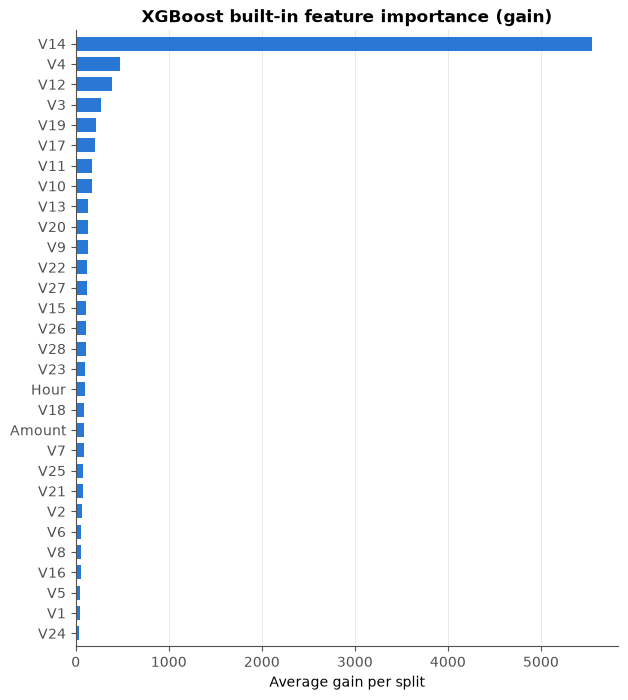

V14    5553.161621
V4      474.667999
V12     391.826355
V3      271.124634
V19     214.253662
V17     210.831863
V11     175.506836
V10     170.814774
V13     135.665909
V20     133.924133
dtype: float64

In [8]:
gain = pd.Series(model.get_booster().get_score(importance_type='gain'))
gain = gain.reindex(X_train.columns, fill_value=0).sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(gain.index, gain.values, color='#2a78d6', height=0.7)
ax.set_xlabel('Average gain per split')
ax.set_title('XGBoost built-in feature importance (gain)')
ax.grid(axis='y', visible=False)
ax.margins(y=0.01)
fig.savefig(FIG_DIR / 'xgb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
gain.sort_values(ascending=False).head(10)

## Save the model

In [9]:
model.save_model(MODEL_DIR / 'xgboost.json')
print('Saved', MODEL_DIR / 'xgboost.json')

Saved models/xgboost.json


## SHAP

In [10]:
import warnings
# Harmless library warnings: tqdm's notebook progress bar and a NumPy RNG deprecation inside shap
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', message='The NumPy global RNG', category=FutureWarning)
import shap

# Explain only the trees that predict_proba uses (up to the best iteration)
best_booster = model.get_booster()[: model.best_iteration + 1]
X_shap = X_val.sample(2000, random_state=SEED)
print('SHAP sample:', len(X_shap), 'validation rows,', int(y_val.loc[X_shap.index].sum()), 'of them fraud')

def explain_with_xgboost(X):
    """Fallback from plan Step 26: XGBoost's own SHAP values (last column is the base value)."""
    contribs = best_booster.predict(xgb.DMatrix(X), pred_contribs=True)
    return shap.Explanation(values=contribs[:, :-1], base_values=contribs[:, -1],
                            data=X.values, feature_names=list(X.columns))

try:
    explain = shap.TreeExplainer(best_booster)
    shap_values = explain(X_shap)
    SHAP_SOURCE = f'shap {shap.__version__} TreeExplainer'
except Exception as err:
    # If this happens, log it in docs/decisions.md
    print('shap TreeExplainer failed, using pred_contribs instead:', repr(err))
    explain = explain_with_xgboost
    shap_values = explain(X_shap)
    SHAP_SOURCE = 'xgboost pred_contribs'

# SHAP values plus the base value must add up to the model's log-odds output
margin = model.predict(X_shap, output_margin=True)
gap = np.abs(shap_values.values.sum(axis=1) + shap_values.base_values - margin).max()
print('Source:', SHAP_SOURCE, '| largest additivity gap:', f'{gap:.2e}')
assert gap < 1e-2

SHAP sample: 2000 validation rows, 3 of them fraud
Source: shap 0.54.1 TreeExplainer | largest additivity gap: 1.24e-05


### Summary on 2,000 validation rows

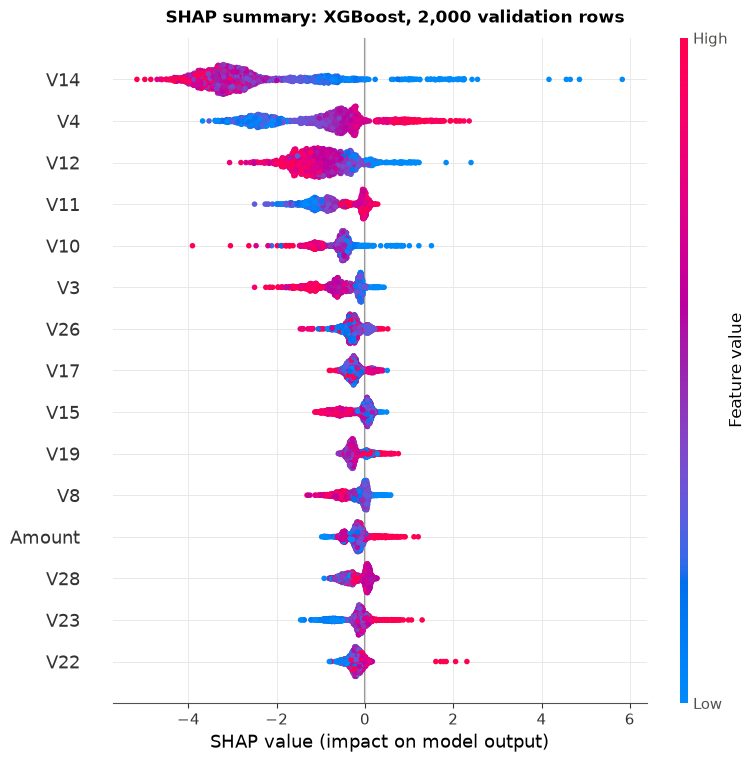

V14    2.791788
V4     1.198476
V12    0.981318
V11    0.656410
V10    0.632166
V3     0.574815
V26    0.289142
V17    0.271002
V15    0.268821
V19    0.267048
Name: mean |SHAP|, dtype: float32

In [11]:
shap.summary_plot(shap_values, X_shap, max_display=15, show=False)
fig = plt.gcf()
fig.suptitle('SHAP summary: XGBoost, 2,000 validation rows', fontweight='bold', y=1.01)
fig.savefig(FIG_DIR / 'xgb_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns)
mean_abs.sort_values(ascending=False).head(10).rename('mean |SHAP|')

### One caught fraud explained

Threshold 0.9394: 69 of 94 validation frauds caught
Case row_id 541 | fraud probability 0.9999


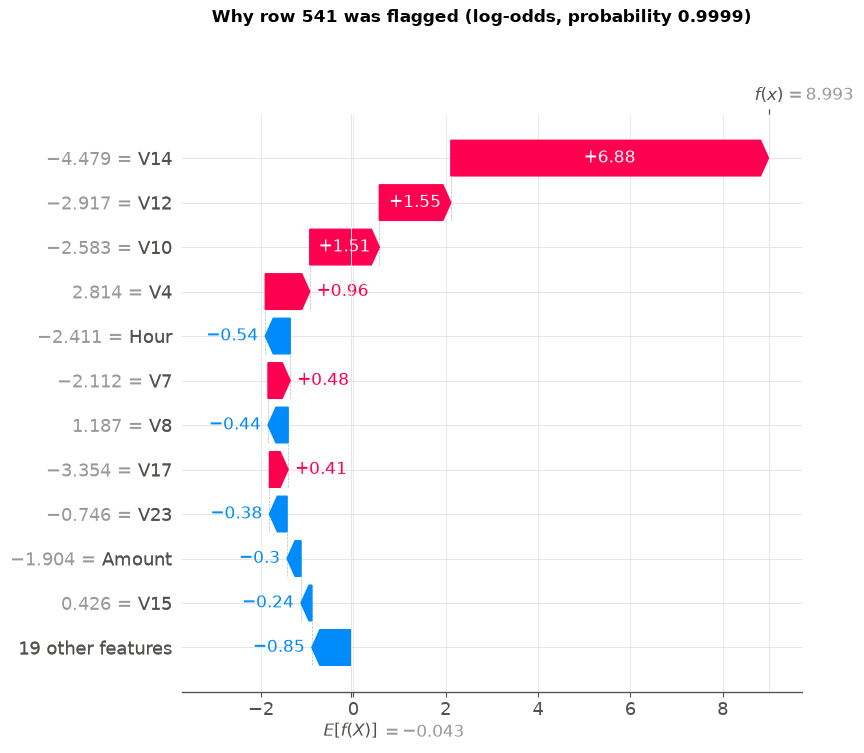

In [12]:
# One fraud that the model caught at the chosen threshold.
# The lowest row_id is taken, so the case is not hand-picked.
threshold = results['threshold']
caught = (y_val.values == 1) & (p_val >= threshold)
print(f'Threshold {threshold:.4f}: {caught.sum()} of {int(y_val.sum())} validation frauds caught')
pos = np.flatnonzero(caught)[np.argmin(rowid_val.values[caught])]
case = X_val.iloc[[pos]]
print(f'Case row_id {rowid_val.iloc[pos]} | fraud probability {p_val[pos]:.4f}')

case_values = explain(case)
shap.plots.waterfall(case_values[0], max_display=12, show=False)
fig = plt.gcf()
fig.suptitle(f'Why row {rowid_val.iloc[pos]} was flagged (log-odds, probability {p_val[pos]:.4f})',
             fontweight='bold', y=1.02)
fig.savefig(FIG_DIR / 'xgb_shap_case.png', dpi=150, bbox_inches='tight')
plt.show()

## Permutation importance

In [13]:
from evaluate import permutation_importance

perm = permutation_importance(lambda X: model.predict_proba(X)[:, 1], X_val, y_val, n_repeats=3)
perm.to_csv('results/perm_xgboost.csv', index=not isinstance(perm.index, pd.RangeIndex))
print('Saved results/perm_xgboost.csv')
perm.head(10)

Saved results/perm_xgboost.csv


,feature,importance_mean,importance_std,baseline_pr_auc
0,V14,0.261115,0.012011,0.789072
1,V4,0.064264,0.006269,0.789072
2,V12,0.057435,0.009038,0.789072
3,V3,0.029112,0.012072,0.789072
4,V11,0.024455,0.000579,0.789072
5,V10,0.017913,0.004086,0.789072
6,V18,0.015434,0.001785,0.789072
7,V7,0.011732,0.002588,0.789072
8,V1,0.009595,0.002063,0.789072
9,Hour,0.009191,0.000592,0.789072


## Package versions

In [14]:
# Exact versions, for pinning requirements/base.txt and requirements/xgboost.txt
from importlib.metadata import version
for pkg in ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn', 'imbalanced-learn', 'shap', 'xgboost']:
    print(f'{pkg}=={version(pkg)}')

pandas==3.1.1
numpy==2.5.4
scikit-learn==1.9.1
matplotlib==3.11.2
seaborn==0.13.2
imbalanced-learn==0.14.2
shap==0.54.1
xgboost==3.4.1
